# Greigite switching response: from reversal curves to a signed density

This is an active maintainer reconstruction of the **complete bound UB199B observation set**. It asks which coercivity and interaction-field responses are supported by measured magnetic moment curves, and how sensitive that answer is to smoothing and noise. This is parameter-space imaging, not a spatial map of the sample.

The review follows six scientific questions: **(1)** what was measured, **(2)** what density and uncertainty mean physically, **(3)** whether a fresh local implementation reproduces an independently executed paper-corrected source, **(4)** whether moment residuals and integral identities are consistent, **(5)** what preprocessing and smoothing change, and **(6)** how added observation noise changes inference. All presented reconstructions below are computed; archived arrays serve only as labeled upstream comparisons.

The paper's historical Figure 4 is context, not a new measurement. This binding retains the current upstream default first points (15,504 observations rather than the paper's 15,364), uses the paper-supported isotropic smoothing family, and selects using 2,000 acquisition positions. It reproduces the six scientific views in that figure without claiming its full 2,646-member anisotropic search. A separately verified scalar source error in the Bayesian normalization is corrected explicitly below.


In [1]:
%matplotlib inline
import os,sys,time,json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.interpolate import LinearNDInterpolator
from scipy.stats import t as student_t
ROOT=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
sys.path.insert(0,str(ROOT))
from src.main import run
from src.preprocessing import preprocess
from src.solvers import reconstruct,vari_weights
from src.physics_model import design_matrix
from src.visualization import metrics,density_plot,local_consistency
plt.rcParams.update({'figure.dpi':120,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
with np.load(ROOT/'data/raw_data.npz',allow_pickle=False) as f:
    raw={k:f[k][0] for k in f.files}
state=preprocess(raw)
print('Acquired samples:',len(raw['moment']),'branches:',len(np.unique(raw['curve_index'])))
print('Actual last-branch increment (T):',state['dH'],'opening field (T):',state['Hopen'])
import scipy,matplotlib
print('Kernel numerical versions:',np.__version__,scipy.__version__,matplotlib.__version__)


Acquired samples: 15504 branches: 140
Actual last-branch increment (T): 0.0018481459602649008 opening field (T): 0.1141267
Kernel numerical versions: 2.4.6 1.17.1 3.11.1


## 1. Observation and hidden-reference roles

The vibrating-sample instrument records magnetic moment $m$ in A m² at applied induction $B$ and reversal induction $B_r$, both in tesla. The complete 140-branch observation includes different samples along each increasing-field branch. The instrument's published domain fixes 11,310 output positions *before fitting*; all 15,504 acquired moments can contribute neighboring information.

There is no measured ground-truth switching density. Independent upstream executions are **method references**. They are never labeled physical truth. No fully sampled target, postfit quality mask or cached density enters the visible observations.


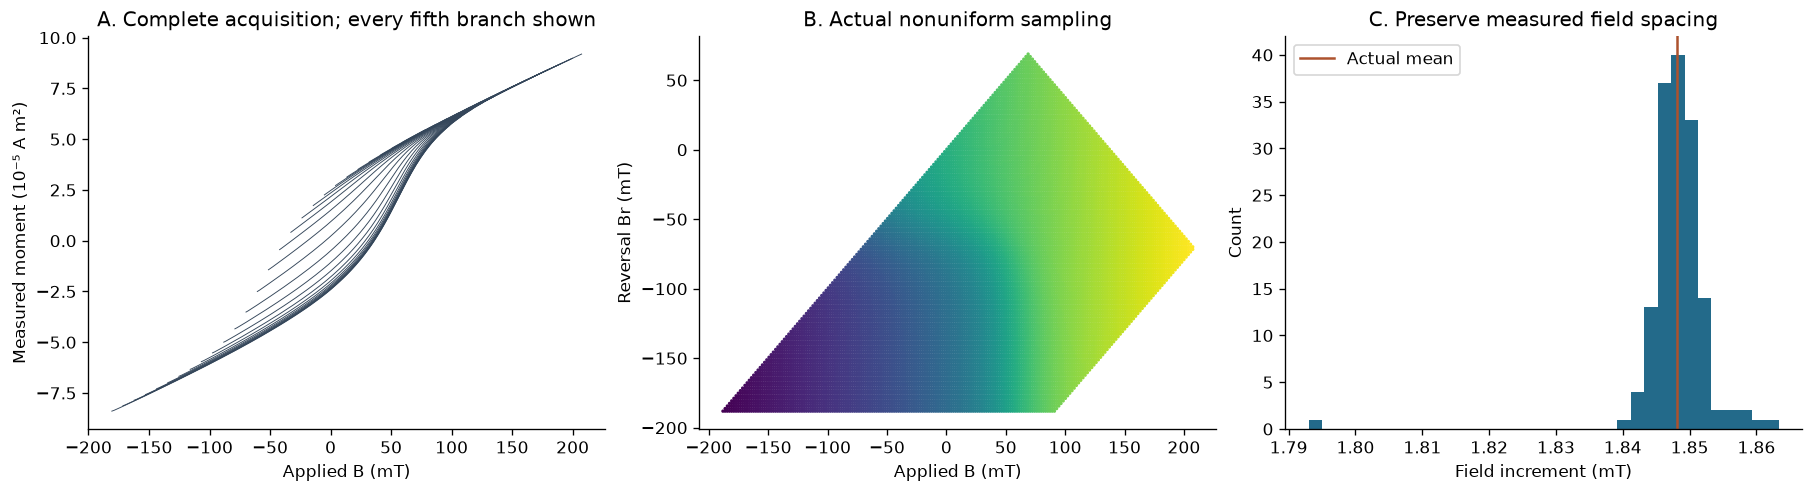

In [2]:
fig,axes=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
for curve in np.unique(raw['curve_index'])[::5]:
    q=raw['curve_index']==curve
    axes[0].plot(raw['field'][q]*1e3,raw['moment'][q]*1e5,color='#34465a',lw=.55)
axes[0].set(xlabel='Applied B (mT)',ylabel='Measured moment (10⁻⁵ A m²)',title='A. Complete acquisition; every fifth branch shown')
axes[1].scatter(raw['field']*1e3,raw['reversal_field']*1e3,c=raw['moment'],s=1,cmap='viridis',rasterized=True)
axes[1].set(xlabel='Applied B (mT)',ylabel='Reversal Br (mT)',title='B. Actual nonuniform sampling')
axes[2].hist(np.diff(raw['field'][raw['curve_index']==np.max(raw['curve_index'])])*1e3,bins=35,color='#236a8a')
axes[2].axvline(state['dH']*1e3,color='#ad522e',label='Actual mean');axes[2].legend()
axes[2].set(xlabel='Field increment (mT)',ylabel='Count',title='C. Preserve measured field spacing')
plt.show()


## 2. Physical inverse and its uncertainty

The unknown is the signed response

$$\rho=-\frac12\frac{\partial^2M}{\partial B\partial B_r},\qquad B_c=(B-B_r)/2,\qquad B_u=(B+B_r)/2.$$

A quadratic local moment surface has columns $[1,B,B_r,B^2,B_r^2,BB_r]$ and coefficient vector $\beta$. Thus $\rho=-\beta_5/2$. Weighted least squares estimates $\beta$ from nearby measured moments. The estimated local residual variance is $s^2=\mathrm{RSS}/(n-6)$ for $n$ neighbors, and covariance is $C=s^2(X^TWX)^{-1}$. The conditional one-standard-error is $\sqrt{C_{55}}/2$.

These uncertainties are conditional on the selected smoothing/model, not an independent calibration of physical accuracy and not an account of every selection uncertainty. The source sets both density and SE to zero when no mixed-derivative model is supported; that convention does not mean the specimen's response is known with zero physical uncertainty.

Marginal functions depending only on $B$ or only on $B_r$ have zero mixed derivative. High-field susceptibility and lower-branch corrections use this property. Recovering density alone does not determine an absolute global moment surface without those marginal boundary functions.

**Disclosed source correction.** Paper Appendix A uses $a=-3/4$ and four nonintercept terms for the derivative-free quadratic. Its normalization is $\Gamma(9/4)/\Gamma(1/4)=5/16$, following twice from $\Gamma(z+1)=z\Gamma(z)$. The archived source instead uses $1/4$. The independent paper-corrected oracle changes only this scalar log normalization by $\log(1.25)$; original and corrected source outputs are compared separately below. The historical claim of unchanged upstream reproduction is explicitly not made.


## 3. Fresh reconstruction and six views of the scientific result

The next cell calls the complete standard entry point on the raw observations and writes a fresh submission. It then compares that newly computed density and SE with independent paper-corrected and unmodified upstream runs. No source-library imports or archived reconstructions substitute for this computation.


In [3]:
fresh=run()
with np.load(ROOT/'notebooks/reference_outputs/upstream_standard.npz',allow_pickle=False) as f:
    corrected={k:f[k] for k in f.files}
with np.load(ROOT/'notebooks/reference_outputs/upstream_unmodified.npz',allow_pickle=False) as f:
    original={k:f[k] for k in f.files}
rows=[]
for name,key in [('Density','reconstruction'),('Conditional SE','standard_error')]:
    v=metrics(fresh[key],corrected[key][0]);rows.append(dict(quantity=name,comparison='Fresh vs independent paper-corrected source',**v))
    v=metrics(fresh[key],original[key][0]);rows.append(dict(quantity=name,comparison='Fresh vs unmodified source',**v))
print(json.dumps({'actual_standard_runtime_seconds':fresh['runtime_seconds'],'selected_smoothing':fresh['selected_smoothing'],'comparisons':rows},indent=2))
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_standard.npz',reconstruction=fresh['reconstruction'][None],standard_error=fresh['standard_error'][None],runtime_seconds=np.array(fresh['runtime_seconds']))
print('Changed native model-order labels after scalar correction:',int(np.count_nonzero(corrected['model_order']!=original['model_order'])))


{
  "actual_standard_runtime_seconds": 9.050888600002509,
  "selected_smoothing": 2.0,
  "comparisons": [
    {
      "quantity": "Density",
      "comparison": "Fresh vs independent paper-corrected source",
      "ncc": 1.0,
      "nrmse": 1.1197936267975746e-14
    },
    {
      "quantity": "Density",
      "comparison": "Fresh vs unmodified source",
      "ncc": 0.9992117208582474,
      "nrmse": 0.004518187017950034
    },
    {
      "quantity": "Conditional SE",
      "comparison": "Fresh vs independent paper-corrected source",
      "ncc": 0.9999999999999999,
      "nrmse": 1.1011270111430757e-09
    },
    {
      "quantity": "Conditional SE",
      "comparison": "Fresh vs unmodified source",
      "ncc": 0.9891300983856541,
      "nrmse": 0.02077039734221379
    }
  ]
}
Changed native model-order labels after scalar correction: 110


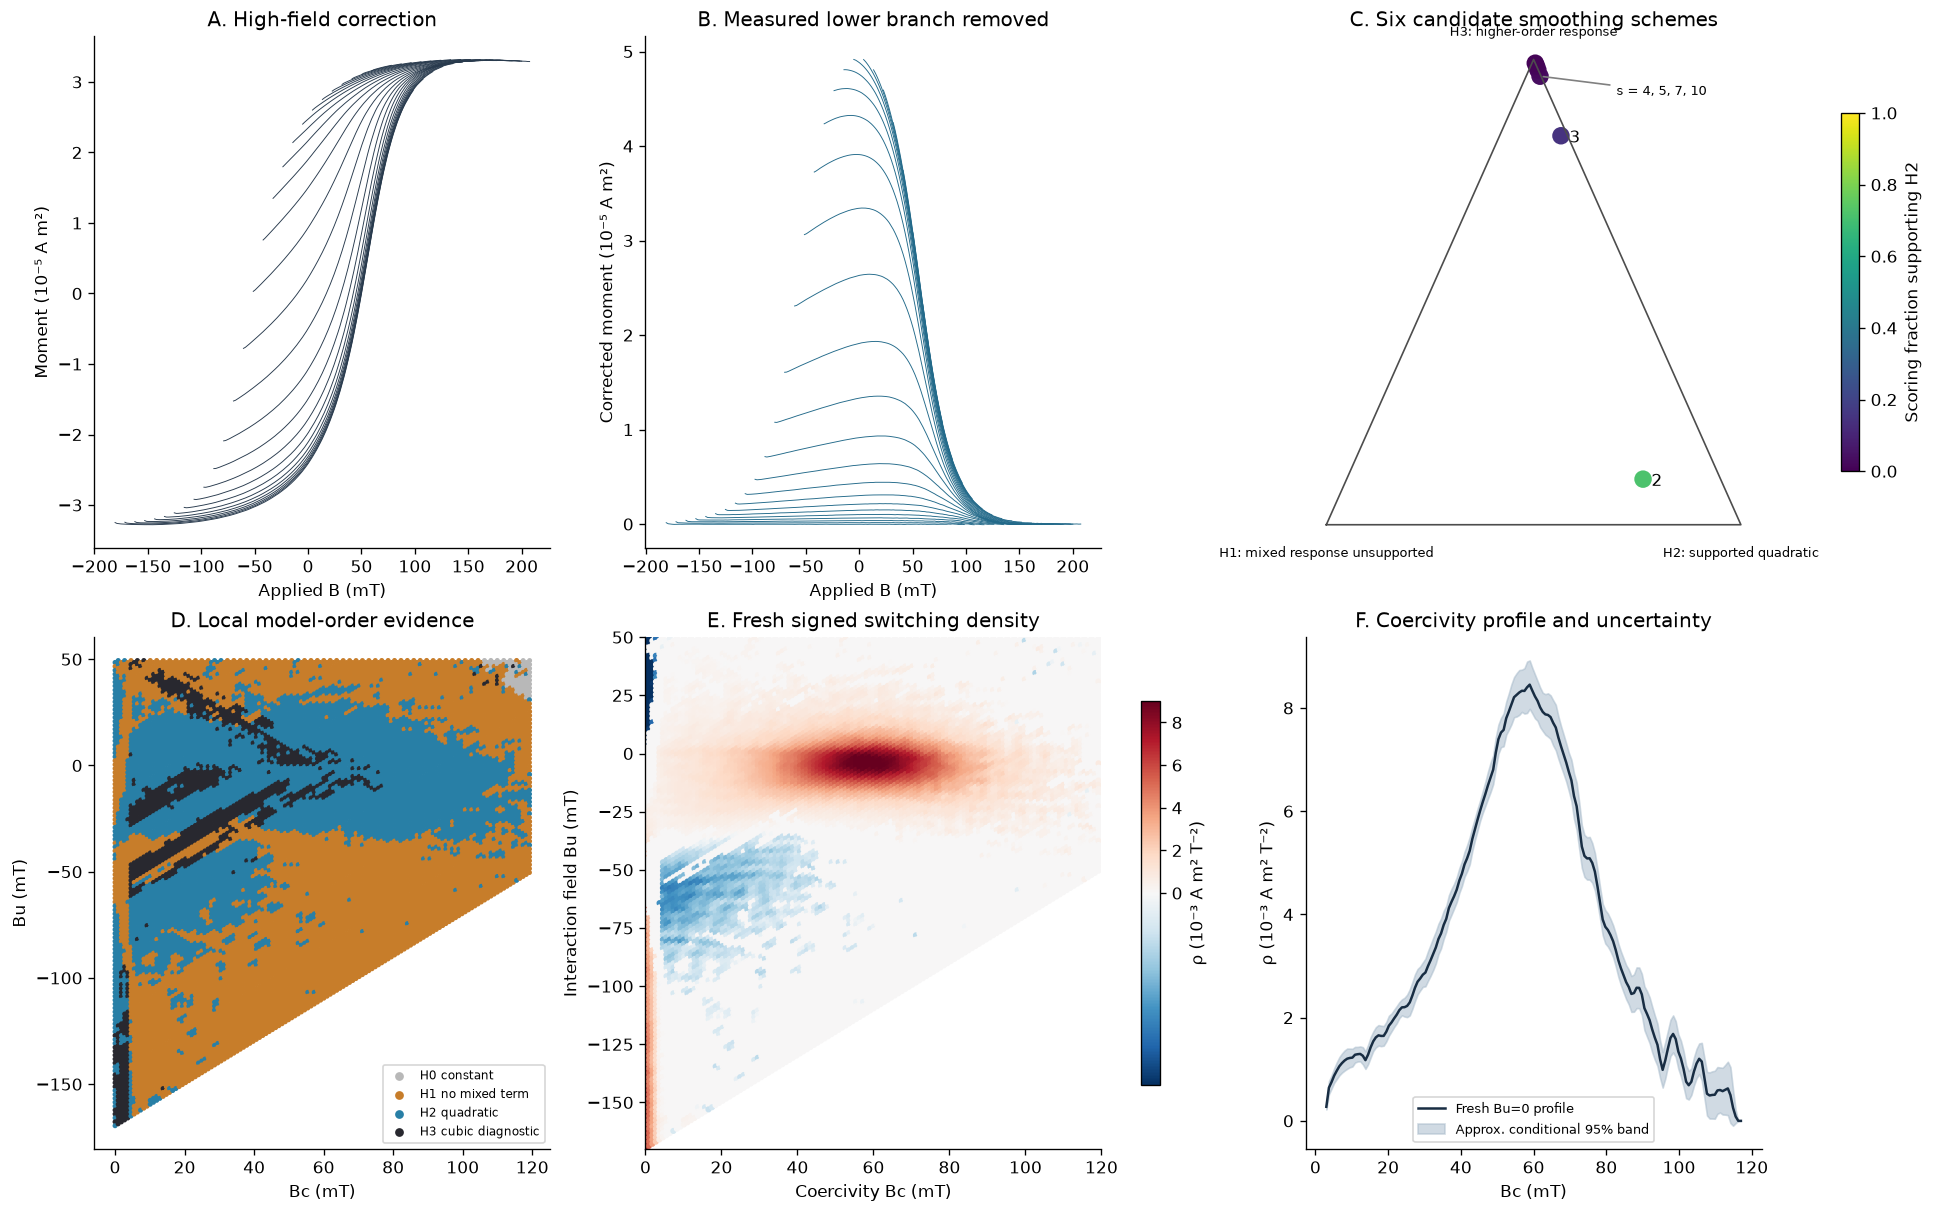

Candidate scores [H0,H1,H2,H3]: {'2': [0, 374, 1430, 196], '3': [0, 32, 296, 1672], '4': [0, 5, 67, 1928], '5': [0, 2, 43, 1955], '7': [0, 0, 28, 1972], '10': [0, 0, 16, 1984]}


In [4]:
j=fresh['domain_indices'];hc=(state['H'][j]-state['Hr'][j])/2;hu=(state['H'][j]+state['Hr'][j])/2
fig,axes=plt.subplots(2,3,figsize=(16,10),constrained_layout=True)
for curve in np.unique(state['Fk'])[::5]:
    q=state['Fk']==curve
    axes[0,0].plot(state['H'][q]*1e3,state['M'][q]*1e5,color='#283a4d',lw=.55)
    axes[0,1].plot(state['H'][q]*1e3,state['DM'][q]*1e5,color='#236a8a',lw=.55)
axes[0,0].set(xlabel='Applied B (mT)',ylabel='Moment (10⁻⁵ A m²)',title='A. High-field correction')
axes[0,1].set(xlabel='Applied B (mT)',ylabel='Corrected moment (10⁻⁵ A m²)',title='B. Measured lower branch removed')
# A ternary model-selection comparison preserves the paper's scientific view.
counts=fresh['smoothing_scores'][:,1:];fractions=counts/counts.sum(axis=1)[:,None]
xy=fractions@np.array([[0.,0.],[1.,0.],[.5,np.sqrt(3)/2]])
triangle=np.array([[0,0],[1,0],[.5,np.sqrt(3)/2],[0,0]])
axes[0,2].plot(triangle[:,0],triangle[:,1],color='.3',lw=1)
sc=axes[0,2].scatter(xy[:,0],xy[:,1],c=fractions[:,1],cmap='viridis',s=90,vmin=0,vmax=1)
for k,label in enumerate([2,3]):axes[0,2].annotate(str(label),xy[k],xytext=(5,-4),textcoords='offset points')
axes[0,2].annotate('s = 4, 5, 7, 10',xy=xy[2],xytext=(.70,.80),fontsize=8,arrowprops={'arrowstyle':'-','color':'.5'})
axes[0,2].text(0,-.06,'H1: mixed response unsupported',ha='center',fontsize=8)
axes[0,2].text(1,-.06,'H2: supported quadratic',ha='center',fontsize=8)
axes[0,2].text(.5,.91,'H3: higher-order response',ha='center',fontsize=8)
axes[0,2].set(title='C. Six candidate smoothing schemes');axes[0,2].axis('off')
fig.colorbar(sc,ax=axes[0,2],label='Scoring fraction supporting H2',shrink=.7)
order=np.argmax(fresh['bayes_factors'],axis=1)
colors=['#b8b8b8','#c77d2a','#287fa6','#28282f']
axes[1,0].scatter(hc*1e3,hu*1e3,c=order,cmap=ListedColormap(colors),vmin=-.5,vmax=3.5,s=4,rasterized=True)
for k,label in enumerate(['H0 constant','H1 no mixed term','H2 quadratic','H3 cubic diagnostic']):axes[1,0].scatter([],[],c=colors[k],label=label,s=18)
axes[1,0].legend(fontsize=7,loc='lower right');axes[1,0].set(xlabel='Bc (mT)',ylabel='Bu (mT)',title='D. Local model-order evidence')
im=density_plot(axes[1,1],state,fresh,title='E. Fresh signed switching density')
fig.colorbar(im,ax=axes[1,1],label='ρ (10⁻³ A m² T⁻²)',shrink=.75)
# Interpolation here is explicitly for an illustrative Bu=0 profile, never scoring.
rho_interp=LinearNDInterpolator(np.column_stack((hc,hu)),fresh['reconstruction'])
se_interp=LinearNDInterpolator(np.column_stack((hc,hu)),fresh['standard_error'])
x=np.linspace(.003,.117,160);profile=rho_interp(x,np.zeros_like(x));se_profile=se_interp(x,np.zeros_like(x))
axes[1,2].plot(x*1000,profile*1000,color='#182d43',label='Fresh Bu=0 profile')
axes[1,2].fill_between(x*1000,(profile-1.96*se_profile)*1000,(profile+1.96*se_profile)*1000,color='#a3b7c8',alpha=.5,label='Approx. conditional 95% band')
axes[1,2].set(xlabel='Bc (mT)',ylabel='ρ (10⁻³ A m² T⁻²)',title='F. Coercivity profile and uncertainty');axes[1,2].legend(fontsize=8)
plt.show()
print('Candidate scores [H0,H1,H2,H3]:',dict(zip(['2','3','4','5','7','10'],fresh['smoothing_scores'].tolist())))


## 4. Model consistency and independent error checks

For every native position, the local quadratic predicts a measured moment. The next plot shows residuals in the actual observation units. A separate analytic rectangle test checks that a quadratic's mixed finite difference equals its density integral, including its sign and factor of two. This is a local acquisition consistency test; it does not invent unobserved global boundary functions.

The independent audit found an additional exterior-source defect: outside the author's fixed reporting domain, an eight-neighbor rank-deficient fit can reuse a previous density while a cubic evidence formula is undefined at small sample count. That exterior is never claimed here. All native reporting locations are retained and independently tested for valid neighbor count and full-rank quadratic estimation.


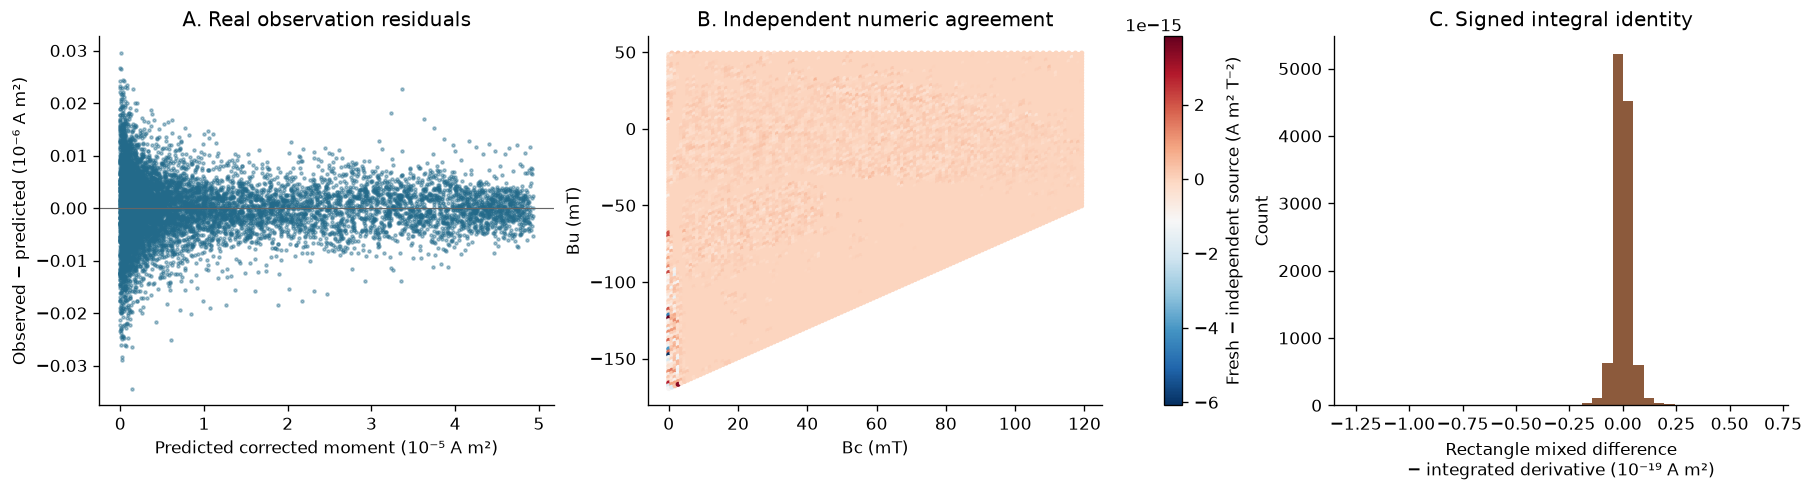

Moment residual / observed corrected dynamic range: 0.00011379181134996997
Largest local integral discrepancy (A m²): 1.255924867651513e-19


In [5]:
consistency=local_consistency(state,fresh)
rho_difference=fresh['reconstruction']-corrected['reconstruction'][0]
fig,axes=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
axes[0].scatter(consistency['moment_prediction']*1e5,consistency['moment_residual']*1e6,s=3,color='#236a8a',alpha=.4,rasterized=True)
axes[0].axhline(0,color='.4',lw=.7);axes[0].set(xlabel='Predicted corrected moment (10⁻⁵ A m²)',ylabel='Observed − predicted (10⁻⁶ A m²)',title='A. Real observation residuals')
im=axes[1].scatter(hc*1000,hu*1000,c=rho_difference,s=4,cmap='RdBu_r',rasterized=True)
fig.colorbar(im,ax=axes[1],label='Fresh − independent source (A m² T⁻²)')
axes[1].set(xlabel='Bc (mT)',ylabel='Bu (mT)',title='B. Independent numeric agreement')
axes[2].hist(consistency['local_integral_error']/1e-19,bins=40,color='#8c5a3c');axes[2].set(xlabel='Rectangle mixed difference'+chr(10)+'− integrated derivative (10⁻¹⁹ A m²)',ylabel='Count',title='C. Signed integral identity')
plt.show()
print('Moment residual / observed corrected dynamic range:',np.sqrt(np.mean(consistency['moment_residual']**2))/np.ptp(state['DM']))
print('Largest local integral discrepancy (A m²):',np.max(np.abs(consistency['local_integral_error'])))


## 5. Actual ablations: smoothing and lower-branch correction

Smoothing is not merely a display setting: it changes the inverse estimate. We actively reconstruct fixed factors 2, 5 and 10 and compare each against the fresh standard result. We also remove the lower-branch correction while retaining high-field correction. This tests the paper's explanation that a correction with zero mixed derivative can still improve finite local approximation. Each ablation remains a fresh method result, not an archived curve or fabricated missing method.


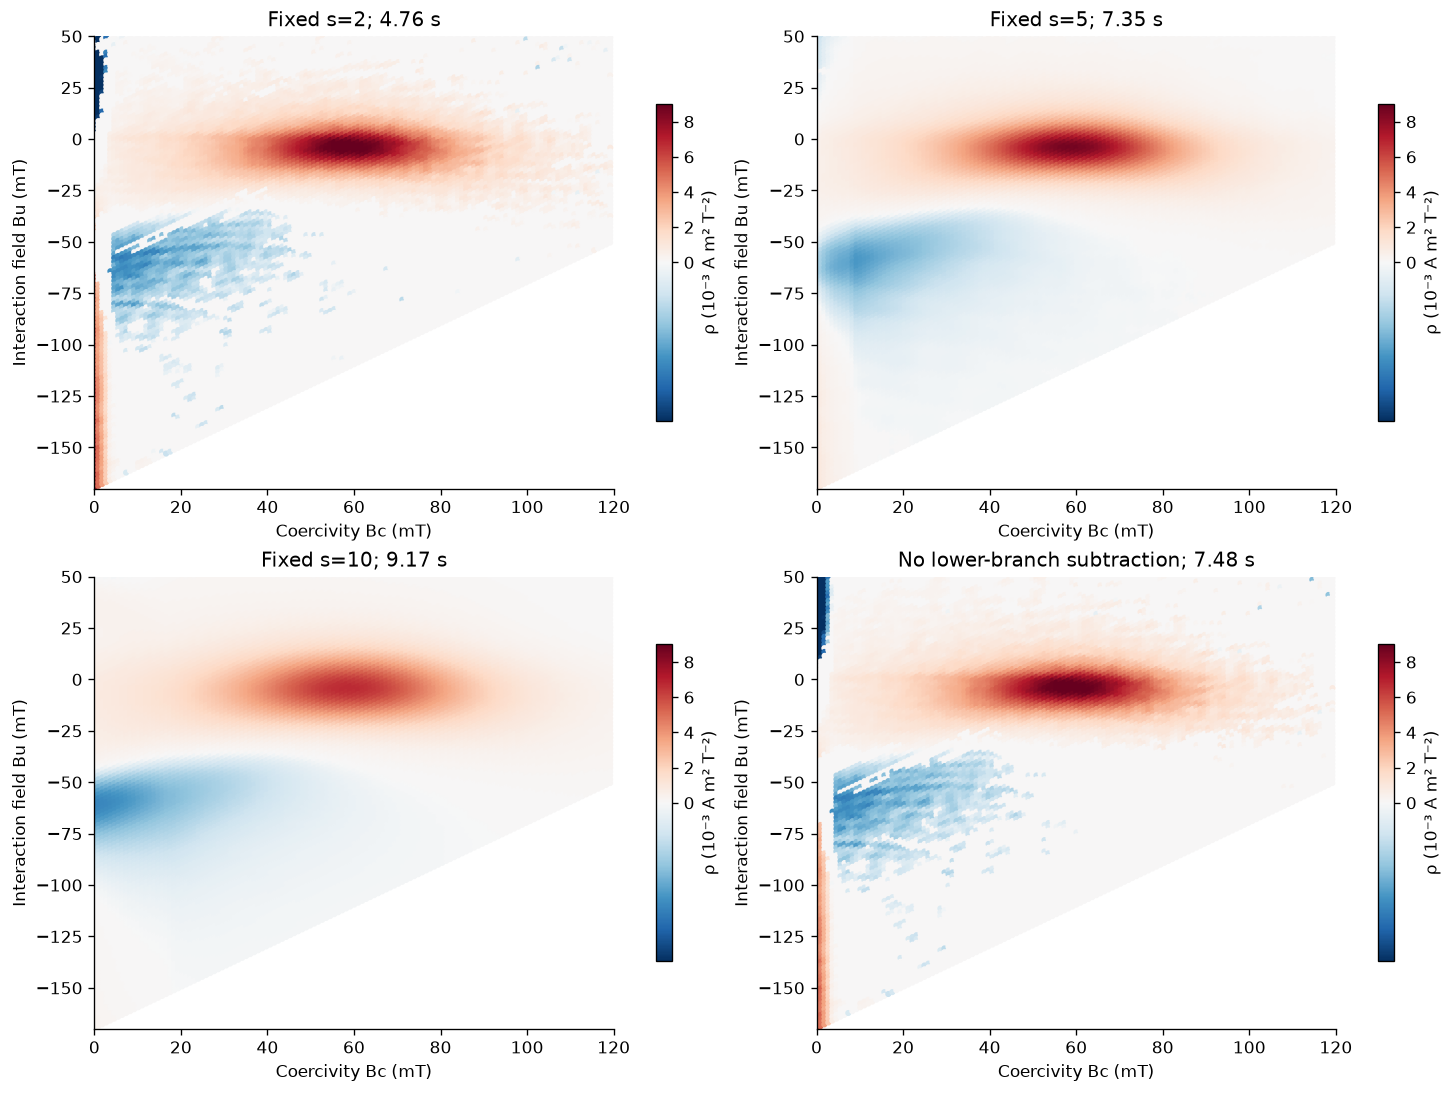

[
  {
    "method": "Fixed s=2",
    "seconds": 4.76370670000324,
    "selected_s": 2.0,
    "ncc": 1.0,
    "nrmse": 0.0
  },
  {
    "method": "Fixed s=5",
    "seconds": 7.3491870000143535,
    "selected_s": 5.0,
    "ncc": 0.9347161728891815,
    "nrmse": 0.04060337866719816
  },
  {
    "method": "Fixed s=10",
    "seconds": 9.169478499970865,
    "selected_s": 10.0,
    "ncc": 0.9012548268412774,
    "nrmse": 0.04993239207909587
  },
  {
    "method": "No lower-branch subtraction",
    "seconds": 7.479539100022521,
    "selected_s": 2.0,
    "ncc": 0.9973285232313656,
    "nrmse": 0.008316072490394894
  }
]


In [6]:
ablation=[]
for label,factors in [('Fixed s=2',(2.,)),('Fixed s=5',(5.,)),('Fixed s=10',(10.,))]:
    start=time.perf_counter();value=reconstruct(state,smoothing_factors=factors)
    ablation.append((label,value,time.perf_counter()-start))
uncorrected=dict(state);uncorrected['DM']=state['M'].copy()
start=time.perf_counter();no_lower=reconstruct(uncorrected)
ablation.append(('No lower-branch subtraction',no_lower,time.perf_counter()-start))
fig,axes=plt.subplots(2,2,figsize=(12,9),constrained_layout=True)
for ax,(label,result,elapsed) in zip(axes.ravel(),ablation):
    im=density_plot(ax,state,result,title=f'{label}; {elapsed:.2f} s')
    fig.colorbar(im,ax=ax,label='ρ (10⁻³ A m² T⁻²)',shrink=.7)
plt.show()
ablation_table=[dict(method=label,seconds=elapsed,selected_s=result['selected_smoothing'],**metrics(result['reconstruction'],fresh['reconstruction'])) for label,result,elapsed in ablation]
print(json.dumps(ablation_table,indent=2))


## 6. Noise robustness, source correction and conclusions

We add zero-mean Gaussian perturbations to the **observed raw moment**, with standard deviation 0.001, 0.002 and 0.003 times its measured dynamic range. These are review perturbation experiments, not substitute benchmark observations. Each noisy acquisition is preprocessed and reconstructed afresh, with smoothing selected again. The baseline specimen is unchanged and no synthetic ground truth is introduced.

The correction comparison below separately reports the actual effect of the source scalar error. Conclusions must follow the computed tables and views rather than assume every noise experiment improves monotonically.


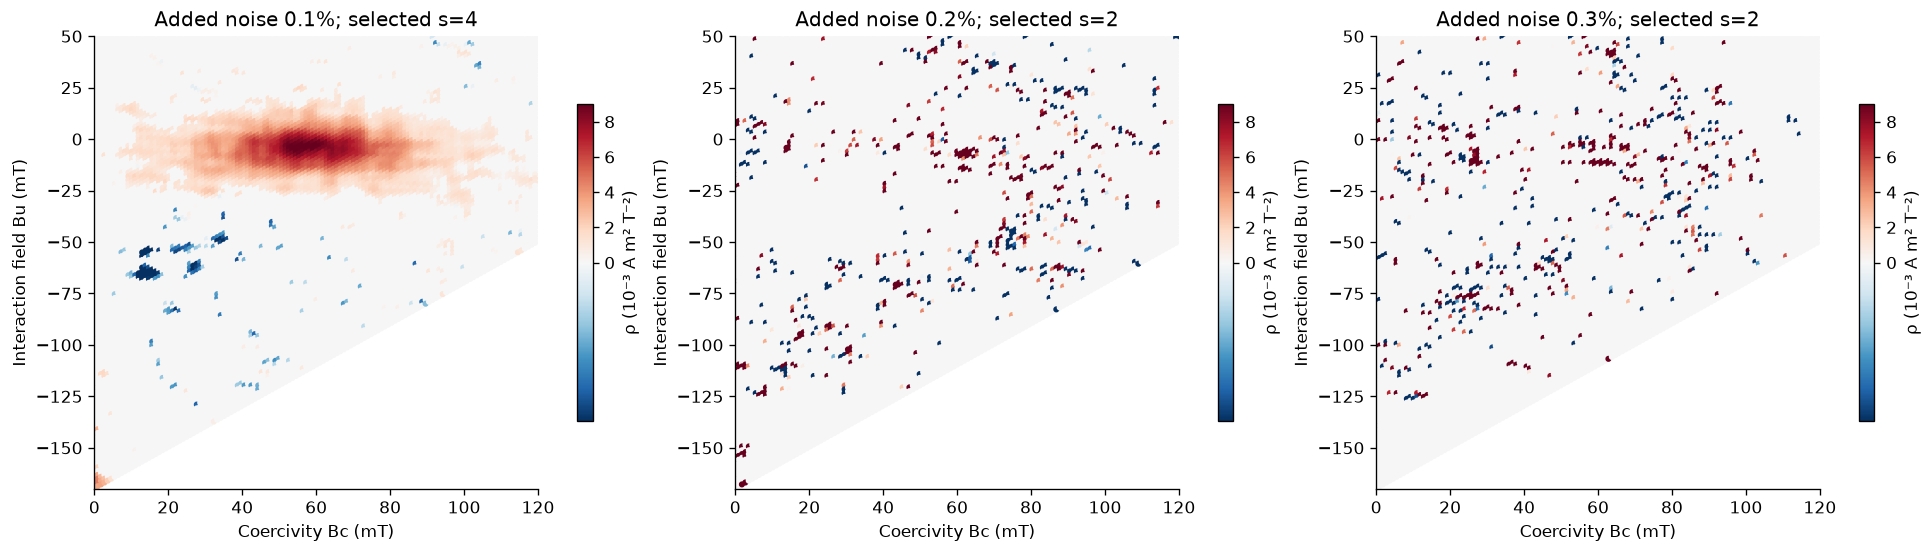

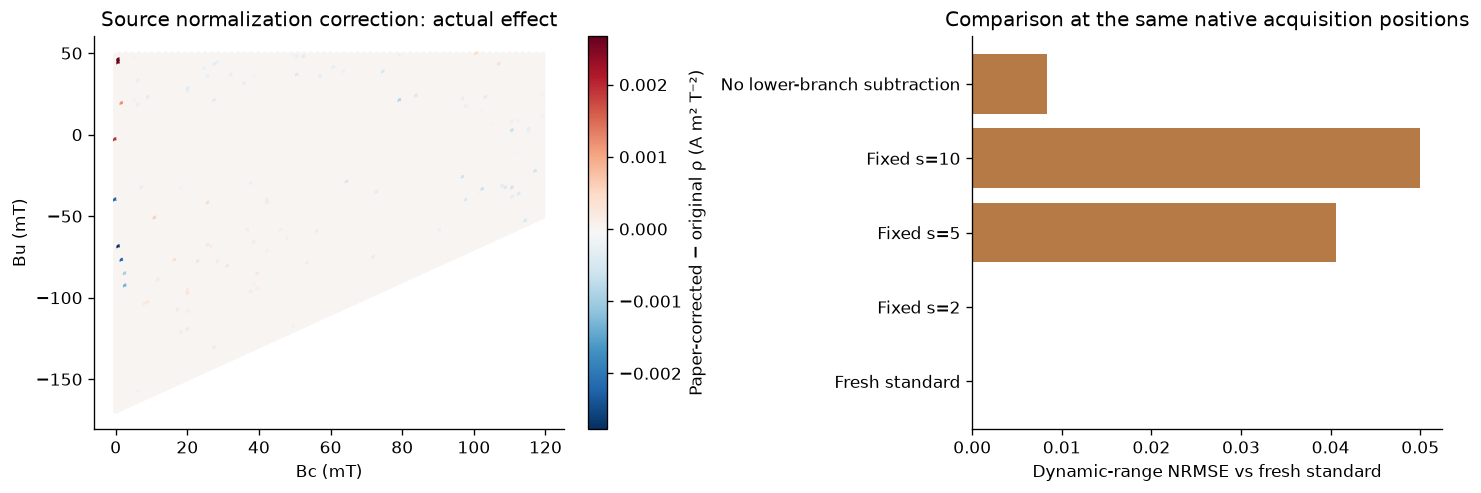

{
  "robustness": [
    {
      "noise_fraction": 0.001,
      "seconds": 8.972054400015622,
      "selected_s": 4.0,
      "ncc": 0.9057934997232593,
      "nrmse": 0.04819570314490877
    },
    {
      "noise_fraction": 0.002,
      "seconds": 8.073072300001513,
      "selected_s": 2.0,
      "ncc": 0.14928761280578237,
      "nrmse": 0.2390559691063662
    },
    {
      "noise_fraction": 0.003,
      "seconds": 8.007321599987336,
      "selected_s": 2.0,
      "ncc": 0.12766402141283523,
      "nrmse": 0.3018027404126421
    }
  ],
  "correction_changed_samples": 109,
  "correction_max_abs_density": 0.0027710978379770386,
  "correction_model_label_changes": 110
}
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 1.0,
    "reconstruction_nrmse": 1.1197936267975746e-14,
    "standard_error_ncc": 0.9999999999999999,
    "standard_error_nrmse": 1.1011270111430757e-09
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boun

In [7]:
rng=np.random.default_rng(20261026)
robust=[]
for noise_fraction in [.001,.002,.003]:
    noisy={k:v.copy() for k,v in raw.items()}
    noisy['moment']+=rng.normal(0.,noise_fraction*np.ptp(raw['moment']),raw['moment'].shape)
    start=time.perf_counter();noisy_state=preprocess(noisy);value=reconstruct(noisy_state)
    robust.append((noise_fraction,noisy_state,value,time.perf_counter()-start))
fig,axes=plt.subplots(1,3,figsize=(16,4.5),constrained_layout=True)
for ax,(noise_fraction,noisy_state,value,elapsed) in zip(axes,robust):
    im=density_plot(ax,noisy_state,value,title=f'Added noise {100*noise_fraction:.1f}%; selected s={value["selected_smoothing"]:g}')
    fig.colorbar(im,ax=ax,label='ρ (10⁻³ A m² T⁻²)',shrink=.7)
plt.show()
robustness_table=[dict(noise_fraction=level,seconds=elapsed,selected_s=value['selected_smoothing'],**metrics(value['reconstruction'],fresh['reconstruction'])) for level,st,value,elapsed in robust]
source_delta=corrected['reconstruction'][0]-original['reconstruction'][0]
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
im=axes[0].scatter(hc*1000,hu*1000,c=source_delta,s=5,cmap='RdBu_r',rasterized=True)
fig.colorbar(im,ax=axes[0],label='Paper-corrected − original ρ (A m² T⁻²)')
axes[0].set(xlabel='Bc (mT)',ylabel='Bu (mT)',title='Source normalization correction: actual effect')
names=['Fresh standard']+[x['method'] for x in ablation_table]
values=[0.]+[x['nrmse'] for x in ablation_table]
axes[1].barh(names,values,color=['#236a8a']+['#b67a46']*4);axes[1].set(xlabel='Dynamic-range NRMSE vs fresh standard',title='Comparison at the same native acquisition positions')
plt.show()
print(json.dumps({'robustness':robustness_table,'correction_changed_samples':int(np.count_nonzero(source_delta)),'correction_max_abs_density':float(np.max(abs(source_delta))),'correction_model_label_changes':int(np.count_nonzero(corrected['model_order']!=original['model_order']))},indent=2))
from importlib.util import spec_from_file_location,module_from_spec
spec=spec_from_file_location('notebook_independent_judge',ROOT/'evaluation/judge.py');judge=module_from_spec(spec);spec.loader.exec_module(judge)
report,exit_code=judge.evaluate(ROOT/'output/reconstruction.npz')
assert exit_code==0,report
print(json.dumps(report,indent=2))


The recovered parameter-space response and conditional uncertainty are supported by actual fresh reconstruction, independently executed corrected-source parity, physical derivative/integral checks and explicit observation residuals. The figures and tables show the consequences of changing smoothing, lower-branch preprocessing and measured-signal noise. They establish reproducibility and estimator sensitivity, while the absence of an independent physical density measurement limits claims of absolute accuracy. The two disclosed upstream defects, acquisition-domain restriction and historical-versus-current preprocessing are recorded in the validation ledger.
